In [1]:
import pyro
from mmbo.training import do_svi
from mmbo.nn import RegBNN, LayeredRegBNN, RegBNNGuide, LayeredRegBNNGuide
from mmbo.nn import posterior_samples
from mmbo.nn import predictor
from mmbo_v1.nn import RegBNN as RegBNN_v1, LayeredRegBNN as LayeredRegBNN_v1, RegBNNGuide as RegBNNGuide_v1, LayeredRegBNNGuide as LayeredRegBNNGuide_v1
from mmbo_v1.training import do_svi as do_svi_v1
from mmbo_v1.nn import posterior_samples as posterior_samples_v1
from mmbo_v1.nn import predictor as predictor_v1

from mmbo.examples.demo import paciorek_demo

import matplotlib.pyplot as plt

# Unpack the included data from dictionary
X_train_main = paciorek_demo["X_train_main"]
X_train_mm =   paciorek_demo["X_train_mm"]
X_test =       paciorek_demo["X_test"]
Y_train_main = paciorek_demo["Y_train_main"]
Y_train_mm =   paciorek_demo["Y_train_mm"]
Y_test_main =  paciorek_demo["Y_test_main"]
Y_test_mm =    paciorek_demo["Y_test_mm"]

c:\Users\itaylor\Documents\DS4MEMS\mmbo\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
# Make sure we're using the package version we want to
from importlib.metadata import version
print(version("mmbo"))
print(version("mmbo_v1"))

2.0.0
1.0.0


In [3]:
learning_rate = 0.001

## Version 2

In [4]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_single = RegBNN.from_data(X_train_main, Y_train_main, hidden_widths = [256, 256], prior_variance = 0.01)

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_single = RegBNNGuide(model_single)

In [5]:


adam = pyro.optim.Adam({"lr": learning_rate})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi = pyro.infer.SVI(model_single, guide_single, adam, elbo)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_single, losses_single = do_svi(svi, params = None, X_train = X_train_main, Y_train = Y_train_main)

2026-10-26 18:05:47 - Start


c:\Users\itaylor\Documents\DS4MEMS\mmbo\.venv\Lib\site-packages\pyro\distributions\torch_distribution.py:49: UserWarning: Singular sample detected.
  self.rsample(sample_shape)


2026-10-26 18:06:12 - Step 1000, Elbo loss: 48153.1 +/- 29408.4 (slope = -50457.740 +/- 429.308 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:06:35 - Step 2000, Elbo loss: 16533.6 +/- 10052.1 (slope = -17227.087 +/- 155.838 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:07:00 - Step 3000, Elbo loss: 5881.9 +/- 3333.8 (slope = -5710.859 +/- 52.783 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:07:48 - Step 4000, Elbo loss: 2319.4 +/- 1135.4 (slope = -1943.258 +/- 18.671 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:08:32 - Step 5000, Elbo loss: 1096.2 +/- 398.7 (slope = -680.056 +/- 7.461 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:09:16 - Step 6000, Elbo loss: 659.1 +/- 150.2 (slope = -252.946 +/- 3.834 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:10:03 - Step 7000, Elbo loss: 495.1 +/- 59.9 (slope = -93.416 +/- 2.841 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:10:44 - Step 8000, Elbo loss: 432.7 +/- 31.8 (slope = -37.117 +/- 2.567 loss/k-iter, p-value = 0.000) + 
2026-10-26 

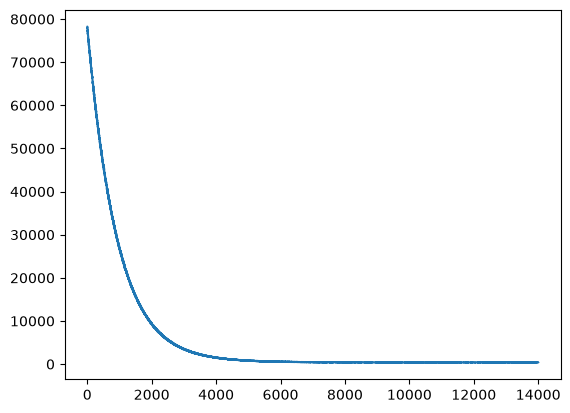

In [6]:
plt.plot(losses_single)

In [7]:

samples_single = posterior_samples(guide_single, params_single, 1000, X_train = X_train_main, Y_train = Y_train_main)

In [8]:
pred_single = predictor(model_single, samples_single)
Y_test_pred_single = pred_single(X_test)
Y_train_pred_single = pred_single(X_train_main)

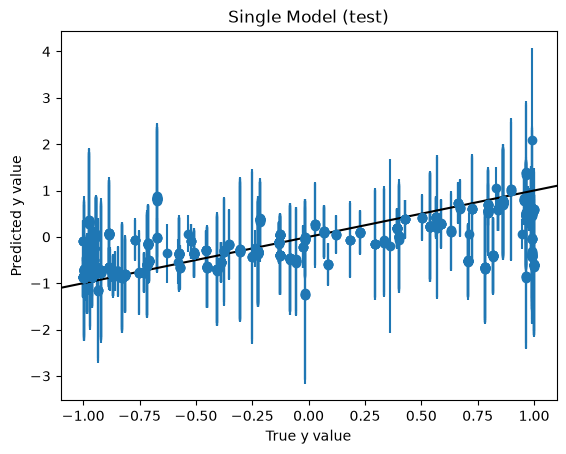

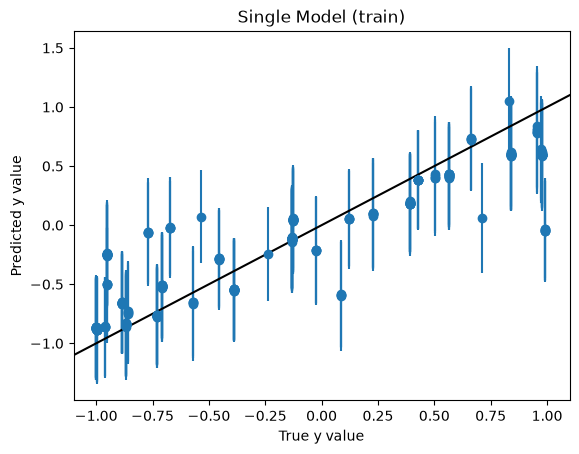

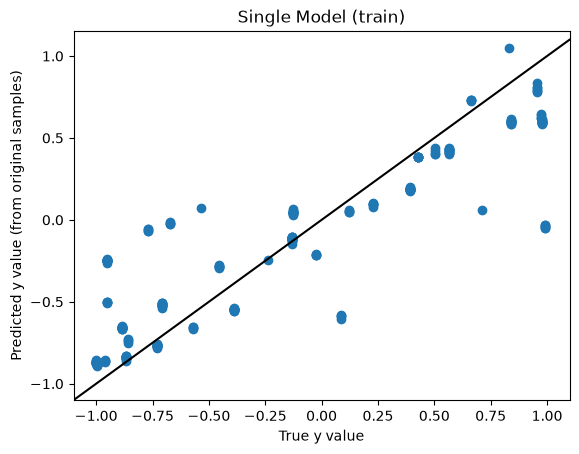

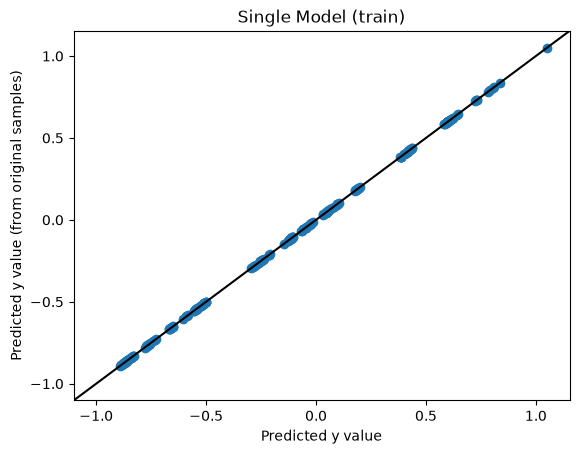

In [9]:
plt.errorbar(Y_test_main, Y_test_pred_single.mean(dim=0).squeeze(), yerr = 1.96 * Y_test_pred_single.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_test_main, Y_test_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.errorbar(Y_train_main, Y_train_pred_single.mean(dim=0).squeeze(), yerr = 1.96 * Y_train_pred_single.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_train_main, Y_train_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.scatter(Y_train_main, samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

plt.scatter(Y_train_pred_single.mean(dim=0), samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("Predicted y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

## Version 1

In [10]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_single_v1 = RegBNN_v1.from_data(X_train_main, Y_train_main, hidden_widths = [256, 256], prior_variance = 0.01)

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_single_v1 = RegBNNGuide_v1(model_single_v1)

In [11]:
adam_v1 = pyro.optim.Adam({"lr": learning_rate})
elbo_v1 = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi_v1 = pyro.infer.SVI(model_single_v1, guide_single_v1, adam_v1, elbo_v1)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_single_v1, losses_single_v1 = do_svi_v1(svi_v1, params = None, X_train = X_train_main, Y_train = Y_train_main)

2026-10-26 18:15:11 - Start
2026-10-26 18:15:55 - Step 1000, Elbo loss: 48743.5 +/- 29575.7 (slope = -50745.044 +/- 431.637 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:16:39 - Step 2000, Elbo loss: 16837.7 +/- 10204.5 (slope = -17489.200 +/- 157.745 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:17:24 - Step 3000, Elbo loss: 5999.2 +/- 3421.2 (slope = -5860.637 +/- 54.179 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:18:08 - Step 4000, Elbo loss: 2360.1 +/- 1158.3 (slope = -1983.160 +/- 18.797 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:18:52 - Step 5000, Elbo loss: 1117.8 +/- 401.2 (slope = -683.631 +/- 7.791 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:19:36 - Step 6000, Elbo loss: 679.0 +/- 152.2 (slope = -255.475 +/- 4.099 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:20:21 - Step 7000, Elbo loss: 511.7 +/- 64.0 (slope = -100.070 +/- 3.021 loss/k-iter, p-value = 0.000) + 
2026-10-26 18:21:05 - Step 8000, Elbo loss: 443.8 +/- 35.4 (slope = -44.077 +/- 2.698 loss/k-iter, p-

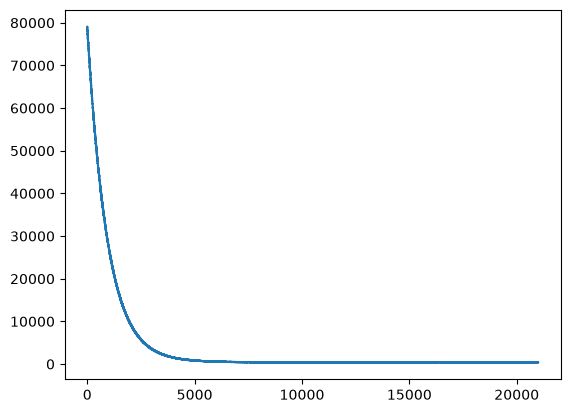

In [12]:
plt.plot(losses_single_v1)

In [13]:
samples_single_v1 = posterior_samples_v1(guide_single_v1, params_single_v1, 1000, X_train = X_train_main, Y_train = Y_train_main)

In [14]:
pred_single_v1 = predictor_v1(model_single_v1, samples_single_v1)
Y_test_pred_single_v1 = pred_single_v1(X_test)
Y_train_pred_single_v1 = pred_single_v1(X_train_main)

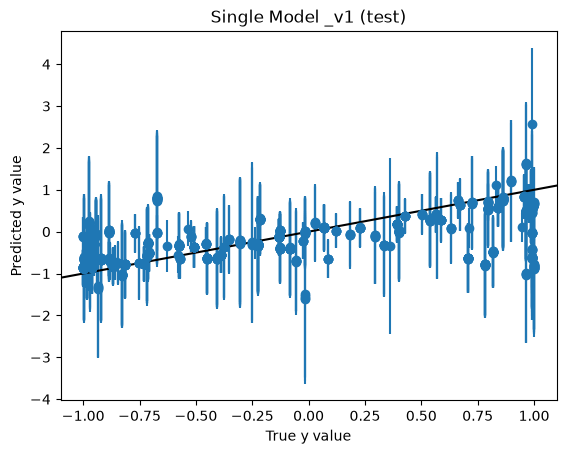

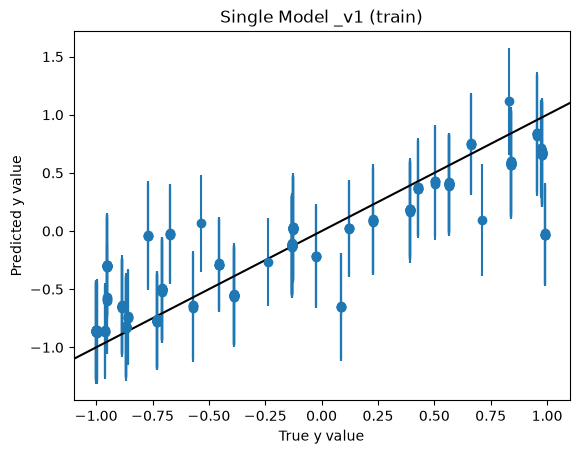

In [15]:
plt.errorbar(Y_test_main, Y_test_pred_single_v1.mean(dim=0).squeeze(), yerr = 1.96 * Y_test_pred_single_v1.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_test_main, Y_test_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model _v1 (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.errorbar(Y_train_main, Y_train_pred_single_v1.mean(dim=0).squeeze(), yerr = 1.96 * Y_train_pred_single_v1.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_train_main, Y_train_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model _v1 (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

## Compare the distributions of stuff

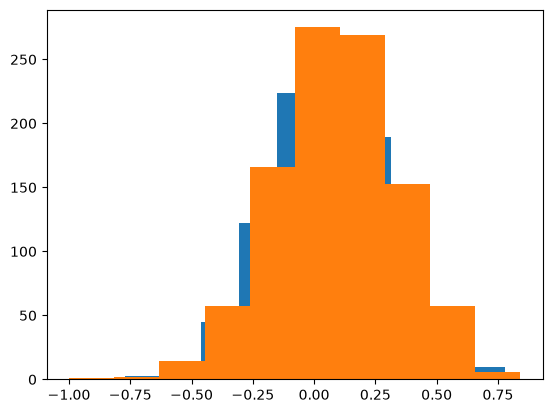

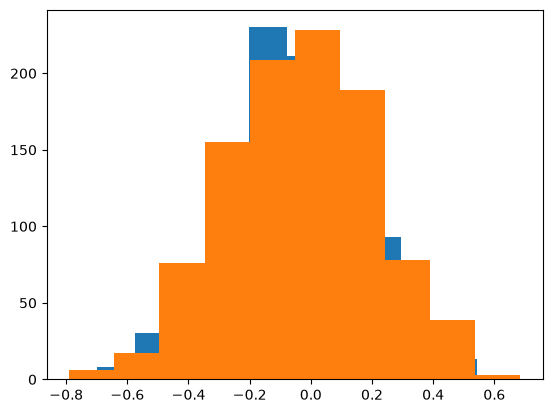

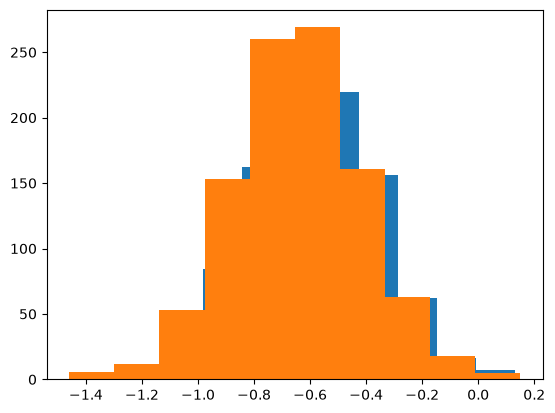

In [18]:
idxs = [0, 1, 2]
for idx in idxs:
    plt.hist(Y_train_pred_single[:,idx,0], label="v2")
    plt.hist(Y_train_pred_single_v1[:,idx,0], label="v1")
    plt.show()